# CommerceIQ — Phase 12 (Model A): Historical Demand & Merchandise Forecasting

**Objective:** Evaluate weekly delivered merchandise value (`merch_brl`) and delivered order volume (`delivered_orders`) forecasting models against classical baselines using chronological train/test splits and expanding-window cross-validation.  
**Historical Framing:** Source records span `2016–2018` (`2017-01-02` to `2018-08-26` for 86 complete Monday-aligned weeks). Results represent **historical backtests and illustrative 8-week continuations**, not current marketplace predictions.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.forecasting.demand_forecasting import run_forecasting_pipeline

res = run_forecasting_pipeline()
print(f"Complete Core Weekly Observations: {res['weekly_rows']} weeks")

Complete Core Weekly Observations: 86 weeks


## 1. Holdout Evaluation (Final 12 Weeks: Jun–Aug 2018)

In [2]:
print("Merchandise Value (BRL) Model Comparison:")
display(res["merch_comparison"])
print("\nOrder Volume Model Comparison:")
display(res["orders_comparison"])

Merchandise Value (BRL) Model Comparison:

Order Volume Model Comparison:


,target,model,MAE,RMSE,WAPE_pct,MAPE_pct
0,merch_brl,Holt_Winters_Trend,36933.64,44108.81,17.97,19.74
1,merch_brl,Moving_Avg_4w,37447.95,45420.54,18.22,21.02
2,merch_brl,ARIMA_111,37718.76,44527.02,18.35,20.42
3,merch_brl,Naive,42718.59,50691.96,20.78,20.42
4,merch_brl,Lag_Ridge,44854.64,54724.38,21.82,20.68
5,merch_brl,Seasonal_Naive_4w,63302.66,74802.84,30.80,34.11


,target,model,MAE,RMSE,WAPE_pct,MAPE_pct
0,delivered_orders,Moving_Avg_4w,256.75,320.28,17.14,17.91
1,delivered_orders,ARIMA_111,287.91,334.70,19.22,19.63
2,delivered_orders,Lag_Ridge,367.28,439.98,24.51,22.59
3,delivered_orders,Holt_Winters_Trend,393.05,448.95,26.23,24.55
4,delivered_orders,Naive,443.92,527.67,29.63,26.82
5,delivered_orders,Seasonal_Naive_4w,465.25,548.13,31.05,33.44


## 2. Expanding-Window Cross-Validation (4 Folds × 4 Weeks) & Forecast Visualization

Saved forecast outputs to data/processed/forecast_outputs.csv and model card to reports/forecasting_model_card.md


,target,model,MAE,RMSE,WAPE_pct,MAPE_pct
3,delivered_orders,Moving_Avg_4w,176.44,199.64,11.87,13.85
0,delivered_orders,ARIMA_111,176.96,203.86,12.00,14.02
2,delivered_orders,Lag_Ridge,234.50,251.98,15.74,17.06
4,delivered_orders,Naive,243.94,274.65,16.65,19.14
1,delivered_orders,Holt_Winters_Trend,249.03,287.36,16.99,19.86
5,delivered_orders,Seasonal_Naive_4w,287.44,327.67,19.57,21.65
10,merch_brl,Naive,23437.48,28017.42,11.00,12.74
6,merch_brl,ARIMA_111,24380.54,26457.92,11.37,12.84
9,merch_brl,Moving_Avg_4w,25743.51,28625.10,12.02,13.66
7,merch_brl,Holt_Winters_Trend,26136.19,30307.63,12.28,14.32


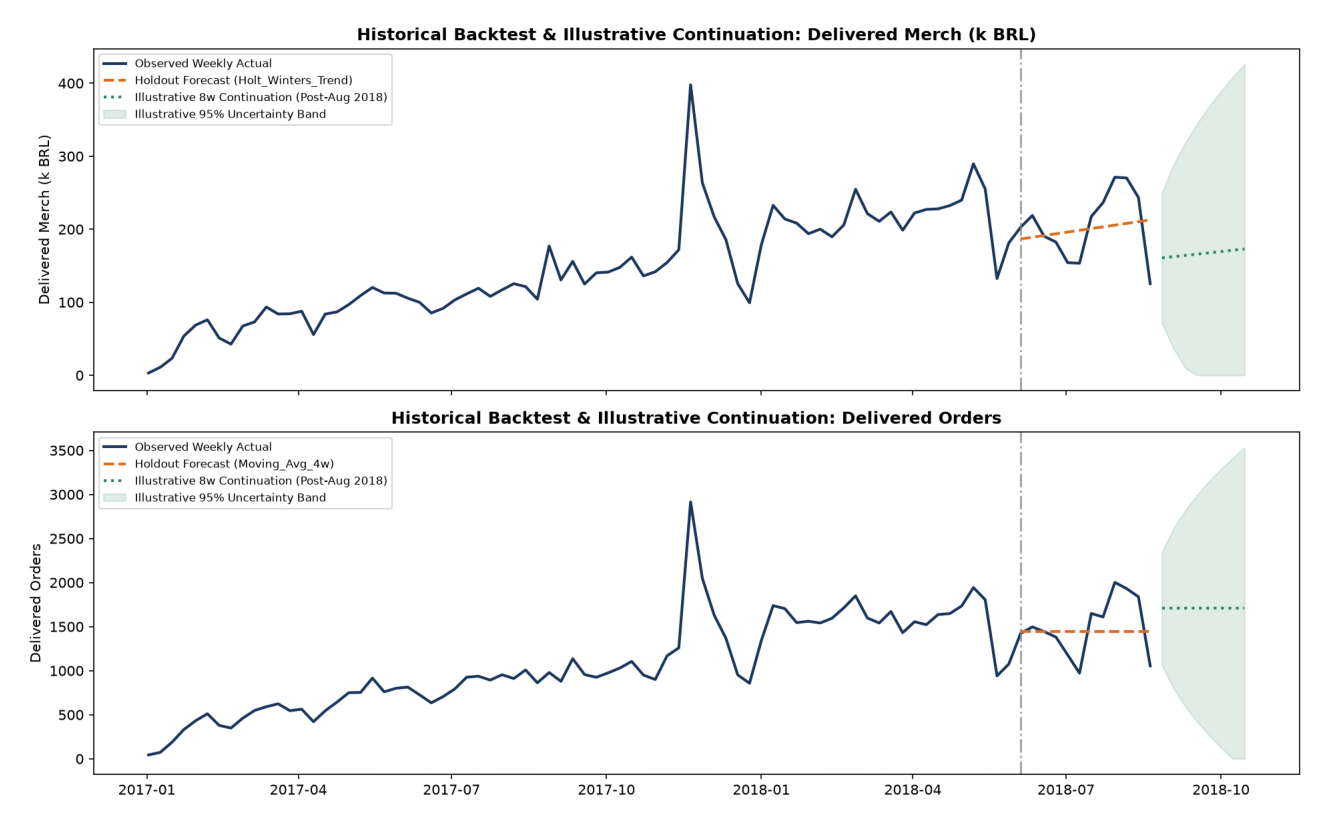

In [3]:
display(res["expanding_cv"])

img = mpimg.imread(PROJECT_ROOT / "reports" / "figures" / "pred_01_demand_forecast_backtest.png")
fig, ax = plt.subplots(figsize=(13, 8))
ax.imshow(img)
ax.axis("off")
plt.show()
print("Saved forecast outputs to data/processed/forecast_outputs.csv and model card to reports/forecasting_model_card.md")